<a href="https://colab.research.google.com/github/bharath-chandra-2719/Walmart-Sales-Forecasting/blob/main/Walmart_Sales_Forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Walmart Store Sales Forecasting
### Applied Predictive Analytics — Case Study

**Dataset:** Walmart Sales Dataset (Kaggle — `yasserh/walmart-dataset`)

**Goal:** Understand what drives weekly sales across Walmart stores —
seasonality, holidays, and economic conditions — then build a model that
forecasts a store's weekly sales.

This notebook is organized into two parts, matching the presentation:

- **Part 1 — Understanding the problem & the data** (visualizations)
- **Part 2 — Algorithms used to build the sales-forecasting model**

Run the cells in order (Runtime → Run all) inside Google Colab.


## 0. Setup — Install & Import Libraries

In [1]:
# Install kagglehub (only needed once per Colab session)
!pip install -q kagglehub


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", None)


## 1. Load the Dataset

We use **kagglehub** to pull the dataset directly from Kaggle inside Colab
(no manual download needed). The first time you run this in Colab, it may
ask you to authenticate with your Kaggle account — follow the on-screen
instructions (or upload your `kaggle.json` API token if prompted).

> If `kagglehub` download ever fails (e.g. no internet / auth issue), you can
> alternatively search "Walmart Sales Dataset" on Kaggle, download the CSV
> manually, upload it to Colab (folder icon → upload), and just change
> `csv_path` below to its uploaded filename. The expected columns are:
> `Store, Date, Weekly_Sales, Holiday_Flag, Temperature, Fuel_Price, CPI, Unemployment`.


In [3]:
import kagglehub
import os

# Downloads the dataset and returns the local folder path
dataset_path = kagglehub.dataset_download("yasserh/walmart-dataset")
print("Dataset downloaded to:", dataset_path)
print(os.listdir(dataset_path))


Using Colab cache for faster access to the 'walmart-dataset' dataset.
Dataset downloaded to: /kaggle/input/walmart-dataset
['Walmart.csv']


In [4]:
csv_name = [f for f in os.listdir(dataset_path) if f.endswith(".csv")][0]
csv_path = os.path.join(dataset_path, csv_name)

df = pd.read_csv(csv_path)
print("Shape of dataset:", df.shape)
df.head()


Shape of dataset: (6435, 8)


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


## 2. Dataset Overview

The Walmart Sales Dataset contains **weekly sales records for 45 Walmart
stores** across the US, with:

- **`Store`** — store identifier (1-45)
- **`Date`** — the week being reported
- **`Weekly_Sales`** — total sales for that store that week (our prediction target)
- **`Holiday_Flag`** — whether the week includes a major holiday (1) or not (0)
- **`Temperature`** — average regional temperature that week
- **`Fuel_Price`** — regional fuel price that week
- **`CPI`** — Consumer Price Index (a measure of inflation)
- **`Unemployment`** — regional unemployment rate

This is a **real-world retail demand forecasting problem** that blends a
time-series element (weekly trends, holiday seasonality) with external
economic factors — exactly the kind of multi-signal problem large retailers
use to plan inventory and staffing.


In [5]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB


In [6]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Store,6435.0,2.300000e+01,12.988182,1.000,12.000,23.000000,3.400000e+01,4.500000e+01
Weekly_Sales,6435.0,1.046965e+06,564366.622054,209986.250,553350.105,960746.040000,1.420159e+06,3.818686e+06
Holiday_Flag,6435.0,6.993007e-02,0.255049,0.000,0.000,0.000000,0.000000e+00,1.000000e+00
Temperature,6435.0,6.066378e+01,18.444933,-2.060,47.460,62.670000,7.494000e+01,1.001400e+02
Fuel_Price,6435.0,3.358607e+00,0.459020,2.472,2.933,3.445000,3.735000e+00,4.468000e+00
CPI,6435.0,1.715784e+02,39.356712,126.064,131.735,182.616521,2.127433e+02,2.272328e+02
Unemployment,6435.0,7.999151e+00,1.875885,3.879,6.891,7.874000,8.622000e+00,1.431300e+01


## 3. Data Cleaning & Feature Engineering

We parse the `Date` column into usable time features (month, week of year,
year) and check for missing values or obvious data issues.


In [7]:
print("Missing values:\n", df.isnull().sum())

df['Date'] = pd.to_datetime(df['Date'], dayfirst=True, errors='coerce')
df = df.dropna(subset=['Date'])

df['Month'] = df['Date'].dt.month
df['Year'] = df['Date'].dt.year
df['WeekOfYear'] = df['Date'].dt.isocalendar().week.astype(int)

print("\nFinal shape after cleaning & feature engineering:", df.shape)
df[['Store', 'Date', 'Weekly_Sales', 'Holiday_Flag', 'Month', 'Year', 'WeekOfYear']].head()


Missing values:
 Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64

Final shape after cleaning & feature engineering: (6435, 11)


,Store,Date,Weekly_Sales,Holiday_Flag,Month,Year,WeekOfYear
0,1,2010-02-05,1643690.90,0,2,2010,5
1,1,2010-02-12,1641957.44,1,2,2010,6
2,1,2010-02-19,1611968.17,0,2,2010,7
3,1,2010-02-26,1409727.59,0,2,2010,8
4,1,2010-03-05,1554806.68,0,3,2010,9


# Part 1 — Visualizations

Five visualizations are used to understand **what drives weekly sales**.


### Visualization 1 — Weekly Sales Distribution

What does a typical week's sales look like across all stores, and how much
variation is there?


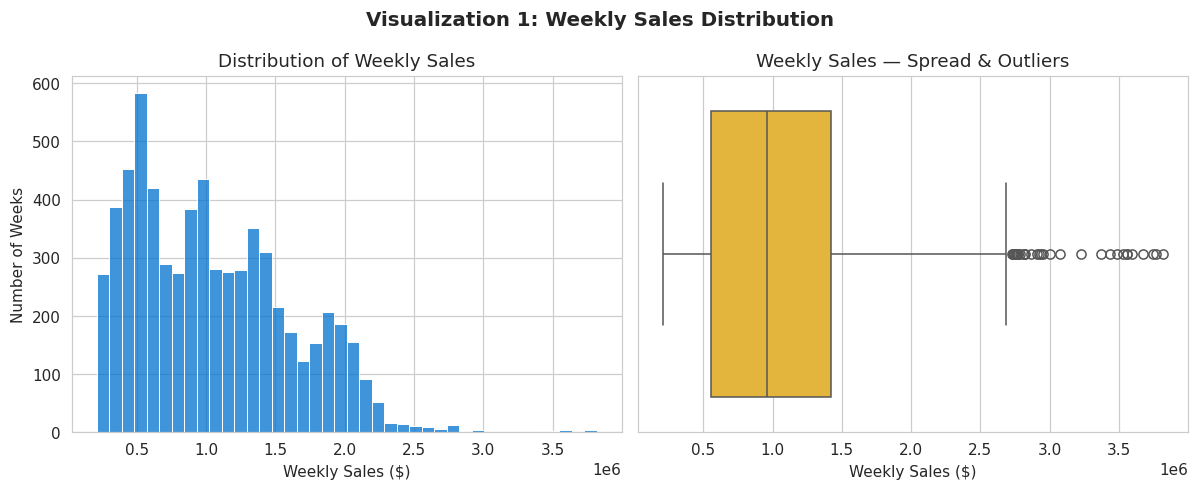

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

sns.histplot(df['Weekly_Sales'], bins=40, color='#0071CE', ax=axes[0])
axes[0].set_title('Distribution of Weekly Sales')
axes[0].set_xlabel('Weekly Sales ($)')
axes[0].set_ylabel('Number of Weeks')

sns.boxplot(x=df['Weekly_Sales'], color='#FFC220', ax=axes[1])
axes[1].set_title('Weekly Sales — Spread & Outliers')
axes[1].set_xlabel('Weekly Sales ($)')

plt.suptitle('Visualization 1: Weekly Sales Distribution', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


**Insight:** Weekly sales vary widely across stores and weeks, with a
right-skewed distribution — most weeks cluster in a moderate range, while a
smaller number of high-volume weeks (larger stores, holiday weeks) pull the
tail upward.


### Visualization 2 — Average Sales by Store

Are all 45 stores performing similarly, or do a handful dominate?


/tmp/ipykernel_1182/2854602622.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=store_avg_sales.index, y=store_avg_sales.values, order=store_avg_sales.index,


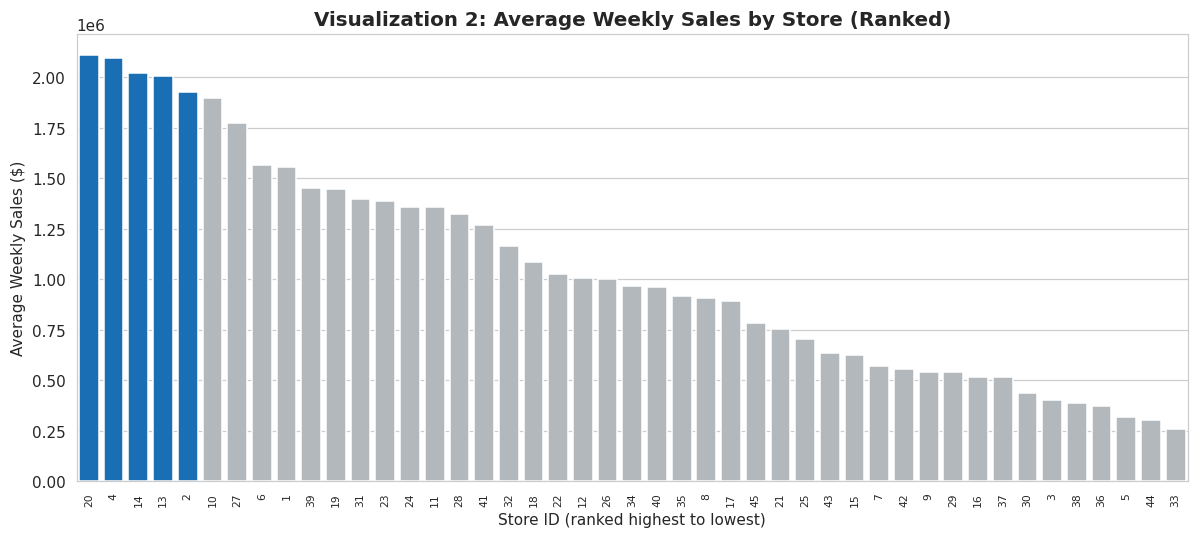

In [9]:
store_avg_sales = df.groupby('Store')['Weekly_Sales'].mean().sort_values(ascending=False)

plt.figure(figsize=(11, 5))
colors = ['#0071CE' if i < 5 else '#B0B8BE' for i in range(len(store_avg_sales))]
sns.barplot(x=store_avg_sales.index, y=store_avg_sales.values, order=store_avg_sales.index,
            palette=colors)
plt.title('Visualization 2: Average Weekly Sales by Store (Ranked)', fontsize=13, fontweight='bold')
plt.xlabel('Store ID (ranked highest to lowest)')
plt.ylabel('Average Weekly Sales ($)')
plt.xticks(rotation=90, fontsize=7)
plt.tight_layout()
plt.show()


**Insight:** Store performance varies substantially — the top 5 stores
(highlighted) average far higher weekly sales than the rest. This kind of
store-level ranking helps regional managers benchmark underperforming
locations against top performers.


### Visualization 3 — Overall Sales Trend Over Time

How does total sales across all stores move week by week? Are there
seasonal spikes?


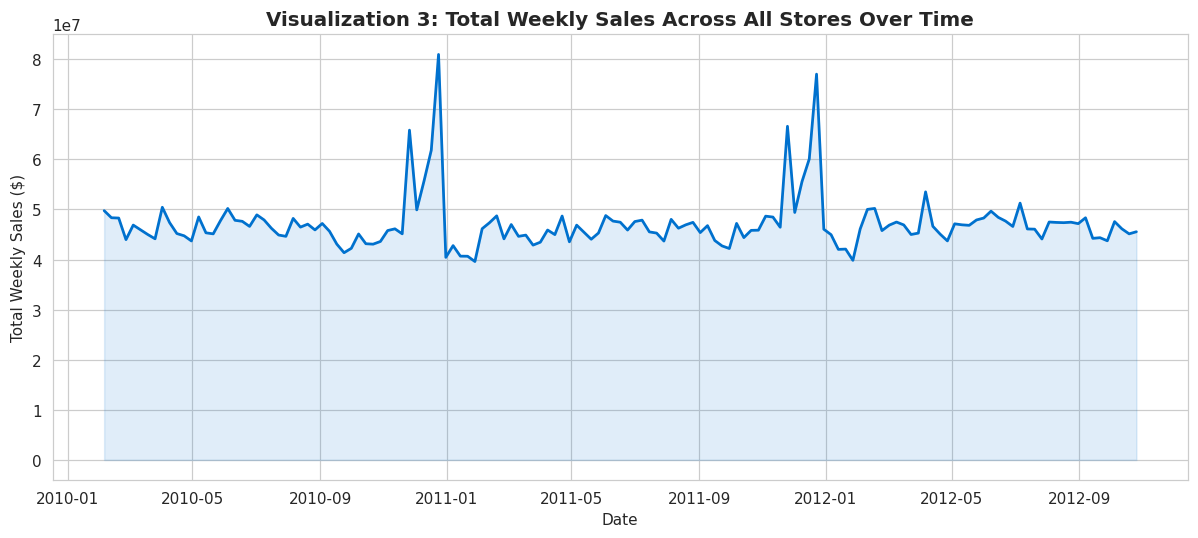

In [10]:
weekly_total = df.groupby('Date')['Weekly_Sales'].sum().sort_index()

plt.figure(figsize=(11, 5))
plt.plot(weekly_total.index, weekly_total.values, color='#0071CE', linewidth=1.8)
plt.fill_between(weekly_total.index, weekly_total.values, alpha=0.12, color='#0071CE')
plt.title('Visualization 3: Total Weekly Sales Across All Stores Over Time', fontsize=13, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Total Weekly Sales ($)')
plt.tight_layout()
plt.show()


**Insight:** Sales show a clear **recurring spike around November-December**
(holiday shopping season) each year, confirming strong seasonality —
critical for inventory planning well ahead of peak weeks.


### Visualization 4 — Holiday vs. Non-Holiday Sales

Do holiday weeks actually generate more sales, and by how much?


/tmp/ipykernel_1182/472310572.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Holiday_Flag', y='Weekly_Sales', data=df, palette=['#B0B8BE', '#FFC220'])


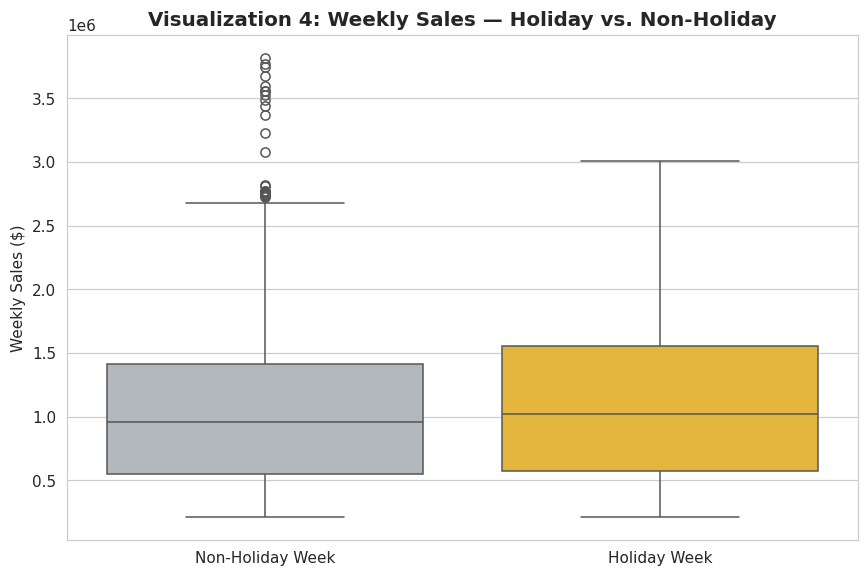

Average sales:
 Holiday_Flag
0    1.041256e+06
1    1.122888e+06
Name: Weekly_Sales, dtype: float64

Holiday weeks generate 7.8% more average sales than non-holiday weeks.


In [11]:
plt.figure(figsize=(8, 5.5))
sns.boxplot(x='Holiday_Flag', y='Weekly_Sales', data=df, palette=['#B0B8BE', '#FFC220'])
plt.xticks([0, 1], ['Non-Holiday Week', 'Holiday Week'])
plt.title('Visualization 4: Weekly Sales — Holiday vs. Non-Holiday', fontsize=13, fontweight='bold')
plt.xlabel('')
plt.ylabel('Weekly Sales ($)')
plt.tight_layout()
plt.show()

holiday_avg = df.groupby('Holiday_Flag')['Weekly_Sales'].mean()
print("Average sales:\n", holiday_avg)
print(f"\nHoliday weeks generate {(holiday_avg[1] / holiday_avg[0] - 1) * 100:.1f}% more average sales than non-holiday weeks.")


**Insight:** Holiday weeks show a noticeably **higher median and more
high-sales outliers** than regular weeks, confirming that Holiday_Flag is a
meaningful signal — not just noise — for forecasting demand.


### Visualization 5 — Correlation Heatmap of Economic Factors

How do temperature, fuel price, CPI, and unemployment relate to weekly
sales?


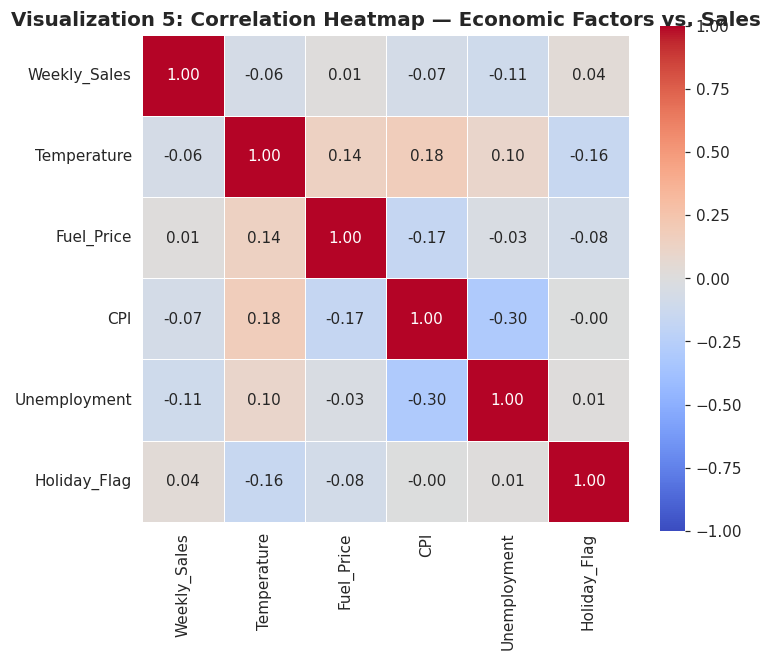

In [12]:
corr_cols = ['Weekly_Sales', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Holiday_Flag']
plt.figure(figsize=(7, 6))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            square=True, linewidths=0.5)
plt.title('Visualization 5: Correlation Heatmap — Economic Factors vs. Sales', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


**Insight:** Weekly sales show only **weak direct correlation** with
temperature, fuel price, CPI, or unemployment individually — sales are
driven far more by *which store* and *which week of the year* it is. This
tells us the predictive model needs store identity and seasonal timing as
core features, with economic indicators as secondary adjustments.

---

## Part 1 Summary

The five visualizations above show that weekly sales are driven mainly by:
1. **Store identity** — some stores consistently outsell others
2. **Seasonality** — a strong, recurring holiday-season spike each year
3. **Holiday weeks** — measurably higher sales than regular weeks
4. **Economic indicators** — a secondary, weaker influence on their own

These patterns are exactly what a retail chain uses to plan inventory and
staffing store-by-store and week-by-week. This motivates **Part 2**:
building an actual model that forecasts a store's weekly sales.


---
# Part 2 — Algorithms Used for Prediction

Having understood the *what* and *why* through visualization, we now build a
model to *forecast* weekly sales. This section covers feature preparation
and the two regression algorithms used: **Linear Regression** and
**Random Forest Regressor**.


## 4. Feature Preparation & Train-Test Split

`Store` is one-hot encoded (each store gets its own indicator column) so
models can learn store-specific baselines without assuming a false ordinal
relationship between store numbers. The data is split 80/20 into training
and test sets.


In [13]:
model_df = pd.get_dummies(df, columns=['Store'], prefix='Store', drop_first=True)

feature_cols = [c for c in model_df.columns if c.startswith('Store_')] + \
               ['Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Month', 'WeekOfYear']

X = model_df[feature_cols]
y = model_df['Weekly_Sales']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training set:", X_train.shape, " Test set:", X_test.shape)


Training set: (5148, 51)  Test set: (1287, 51)


## 5. Algorithm 1 — Linear Regression

**Why:** Linear Regression is a natural baseline — it estimates each store's
baseline sales level plus additive adjustments for holidays, seasonality,
and economic conditions, in a fully interpretable way.


In [15]:
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

y_pred_lr = lin_reg.predict(X_test)

print("=== Linear Regression Performance ===")
print(f"MAE  : {mean_absolute_error(y_test, y_pred_lr):,.2f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test, y_pred_lr)):,.2f}")
print(f"R^2  : {r2_score(y_test, y_pred_lr):.3f}")

=== Linear Regression Performance ===
MAE  : 95,970.25
RMSE : 154,753.68
R^2  : 0.926


## 6. Algorithm 2 — Random Forest Regressor

**Why:** Random Forest captures non-linear, store-specific seasonal effects
(e.g. some stores spike harder at holidays than others) that a linear model
averages away. It also ranks which features matter most.


In [17]:
rf_reg = RandomForestRegressor(n_estimators=300, max_depth=14, random_state=42, n_jobs=-1)
rf_reg.fit(X_train, y_train)

y_pred_rf = rf_reg.predict(X_test)

print("=== Random Forest Performance ===")
print(f"MAE  : {mean_absolute_error(y_test, y_pred_rf):,.2f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test, y_pred_rf)):,.2f}")
print(f"R^2  : {r2_score(y_test, y_pred_rf):.3f}")

=== Random Forest Performance ===
MAE  : 226,358.12
RMSE : 293,475.80
R^2  : 0.733


## 7. Model Comparison — Actual vs. Predicted Sales


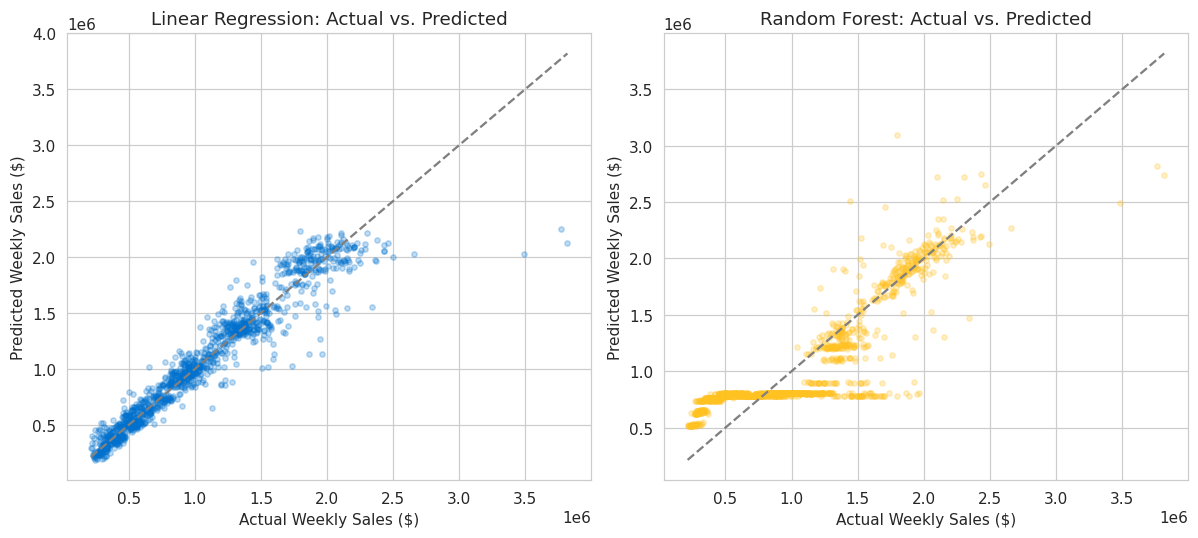

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

for ax, preds, name, color in zip(
    axes, [y_pred_lr, y_pred_rf], ['Linear Regression', 'Random Forest'], ['#0071CE', '#FFC220']
):
    ax.scatter(y_test, preds, alpha=0.25, color=color, s=12)
    lims = [y_test.min(), y_test.max()]
    ax.plot(lims, lims, linestyle='--', color='gray')
    ax.set_title(f'{name}: Actual vs. Predicted')
    ax.set_xlabel('Actual Weekly Sales ($)')
    ax.set_ylabel('Predicted Weekly Sales ($)')

plt.tight_layout()
plt.show()


## 8. Feature Importance (Random Forest)

Which factors does the model rely on most to forecast sales? (Grouped: store
indicators vs. holiday/seasonal/economic features.)


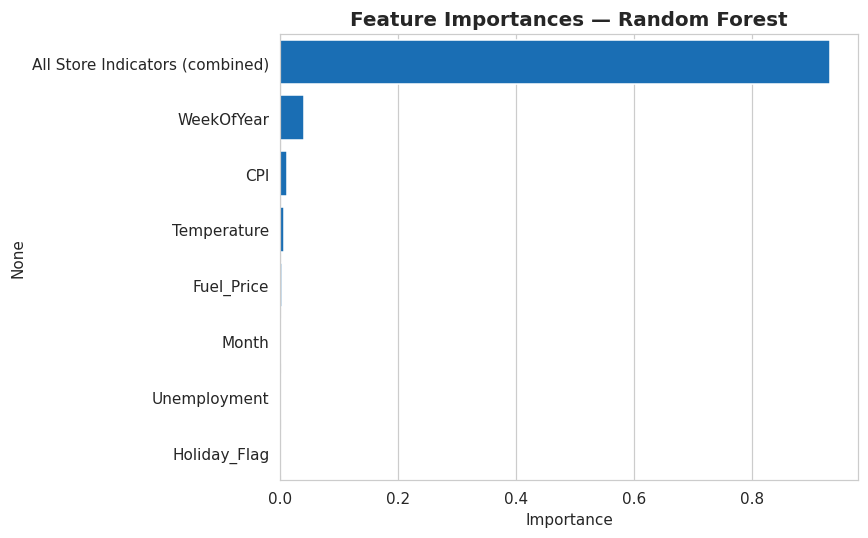

In [19]:
importances = pd.Series(rf_reg.feature_importances_, index=feature_cols)

non_store_importances = importances[~importances.index.str.startswith('Store_')].sort_values(ascending=False)
store_importance_total = importances[importances.index.str.startswith('Store_')].sum()

combined = pd.concat([
    pd.Series({'All Store Indicators (combined)': store_importance_total}),
    non_store_importances
]).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=combined.values, y=combined.index, color='#0071CE')
plt.title('Feature Importances — Random Forest', fontsize=13, fontweight='bold')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()


**Conclusion:** Which store a record belongs to (store identity, combined)
is the single biggest driver of predicted sales, followed by seasonal timing
(week of year, month) and the holiday flag — exactly matching what the Part 1
visualizations revealed. Economic indicators (CPI, fuel price, unemployment,
temperature) contribute smaller, secondary adjustments. This confirms the
visual, exploratory analysis correctly identified the real drivers of sales,
and the predictive model turns those insights into a forecasting tool a
retail chain can use for inventory and staffing decisions weeks in advance.
